(cell_calling)=

# Cell calling

Droplet-based protocols such as 10x Genomics Chromium capture many more barcodes than cells.
Most barcodes mark empty droplets that hold only ambient RNA, the free transcripts of the cell
suspension. Cell calling decides which barcodes hold a cell. It comes before quality control:
quality-control filters and their automatic bounds treat every barcode as a cell, so on an
unfiltered matrix they center on the empty droplets and remove the cells.

`ds.qc.call_cells` implements EmptyDrops [@Lun_2019]. Barcodes with at most `lower` counts, 100
by default, form the ambient pool. Every barcode above `lower` is tested against the ambient
profile: a barcode whose counts the ambient profile explains poorly holds a cell, however few
counts it has. Barcodes with at least as many counts as the knee of the barcode-rank curve are
kept without a test. The test recovers cells with little RNA that a total-count threshold drops.

This page imports an unfiltered 10x matrix, inspects its barcode-rank curve, calls cells, checks
the test statistics, and continues with quality control and the standard analysis on the called
cells. For a matrix whose cells were already called, start with [](quality_control.ipynb).

## Download the raw PBMC matrix

We use the unfiltered matrix of "1k PBMCs from a Healthy Donor (v2 chemistry)" from 10x
Genomics, released under CC BY 4.0. The download is about 18 MB and is checked against a pinned
SHA-256 digest. The example uses a temporary directory; use a project directory instead to keep
the download and the Zarr store.

In [1]:
# Download and verify the raw count file.
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import Request, urlopen

# Work with arrays, tables, and figures.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Import counts and run CyteArc analyses.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's download and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-10-22T16:51:50.760424Z | Wall time: 1.382 s

In [2]:
# Pin the public 10x Genomics file so a changed download cannot alter the example silently.
url = (
    "https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_1k_v2/"
    "pbmc_1k_v2_raw_feature_bc_matrix.h5"
)
expected_digest = "fd258b397faf0e38eed00f8f06f6068cd380963d15e90e25a67c5cd9e19e4f71"
raw_path = output_dir / url.rsplit("/", 1)[1]

# Copy the response in blocks without holding the file in memory. The server refuses
# requests without a user agent of their own.
request = Request(url, headers={"User-Agent": "cytearc-docs"})
with urlopen(request, timeout=60) as response, raw_path.open("wb") as destination:
    shutil.copyfileobj(response, destination)

# Reject a file whose contents differ from the verified source.
with raw_path.open("rb") as source:
    if hashlib.file_digest(source, "sha256").hexdigest() != expected_digest:
        raise ValueError(f"Checksum mismatch for {raw_path.name}")

# Show the size of the completed download.
print(f"Downloaded {raw_path.stat().st_size / 1_000_000:.1f} MB")

Downloaded 18.4 MB


Started: 2026-10-22T16:51:52.146053Z | Wall time: 0.381 s

## Import every barcode with counts

The raw matrix lists every barcode of the chemistry's barcode list, 737,280 for this run, most of
them without a single count. `CrH5Reader(..., is_filtered=False)` keeps the barcodes whose total
exceeds `filtering_cutoff`, 500 by default. That default removes the ambient pool that cell
calling tests against, so pass `filtering_cutoff=0` to keep every barcode with a count. CyteArc
stores counts densely, one row per barcode, so this store is much larger than one of called cells,
and the import takes about half a minute.

We open the store with `min_features_per_cell=-1`. Cell calling reads every barcode whatever the
`I` cell key holds, so the open-time feature floor cannot remove the ambient pool. The default
floor would remove most barcodes, so the first open would keep `I` complete and warn instead;
turning the floor off keeps `I` complete without the warning.

In [3]:
# Keep every barcode with at least one count: the low ones form the ambient pool.
reader = cytearc.CrH5Reader(str(raw_path), is_filtered=False, filtering_cutoff=0)

# Write the converted count store.
store = output_dir / "pbmc_1k_raw.zarr"
cytearc.CrToZarr(reader, zarr_loc=str(store)).dump()

# Open the store and keep every barcode in I.
ds = cytearc.DataStore(str(store), min_features_per_cell=-1)

# Summarize the barcodes by their total counts.
totals = ds.cells.fetch_all("RNA_nCounts")
pd.Series(
    {
        "Barcodes with counts": len(totals),
        "Barcodes with more than 100 counts": int((totals > 100).sum()),
        "Barcodes with more than 1,000 counts": int((totals > 1000).sum()),
    },
    name="Barcodes",
)

Barcodes with counts                    142324
Barcodes with more than 100 counts        1191
Barcodes with more than 1,000 counts       961
Name: Barcodes, dtype: int64

Started: 2026-10-22T16:51:52.530463Z | Wall time: 32.631 s

## Inspect the barcode-rank curve

Ranking barcodes by their total count gives the barcode-rank curve. Cells form a plateau of large
totals, and the curve then drops steeply towards the empty droplets. `qc.barcode_ranks` fits a
smoothing spline to the log-log curve above `lower` and reports two of its points: the knee, where
the plateau bends into the drop, and the inflection, where the curve falls most steeply. It reads
the totals stored when the store was prepared, not the counts.

`qc.call_cells` keeps the barcodes at or above the knee as cells without a test: a barcode with
that many counts holds a cell even when its profile resembles the ambient one.

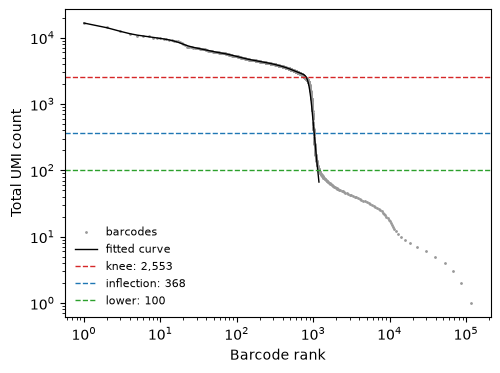

Started: 2026-10-22T16:52:25.164982Z | Wall time: 0.489 s

In [4]:
# Locate the knee and the inflection of the barcode-rank curve.
ranks = ds.qc.barcode_ranks()
curve = ranks.to_pandas()

# Plot every distinct total against its rank on log scales.
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(curve["rank"], curve["total"], ".", markersize=2, color="0.6", label="barcodes")
ax.plot(curve["rank"], curve["fitted"], color="black", linewidth=1, label="fitted curve")

# Mark the knee, the inflection, and the bound of the ambient pool.
for value, name, color in (
    (ranks.knee, "knee", "tab:red"),
    (ranks.inflection, "inflection", "tab:blue"),
    (ranks.lower, "lower", "tab:green"),
):
    ax.axhline(value, color=color, linestyle="--", linewidth=1, label=f"{name}: {value:,.0f}")

# Label the axes and show the figure.
ax.set(xscale="log", yscale="log", xlabel="Barcode rank", ylabel="Total UMI count")
ax.legend(frameon=False, fontsize=8)
plt.show()

## Call cells with EmptyDrops

`qc.call_cells` sums the counts of the ambient pool per gene and smooths them with Good-Turing
estimation, which gives every gene seen in some barcode a nonzero share. It models a barcode's
counts with a Dirichlet-multinomial distribution of that profile, whose precision `alpha` it
estimates from the ambient pool; a small `alpha` means that empty droplets vary more than random
sampling of one profile would make them. For each barcode, `n_iter` simulated ambient count
vectors of its total, 10,000 by default, give the p-value `(R + 1) / (n_iter + 1)`, where `R`
counts those at most as probable as the barcode's own counts. Barcodes at or above the knee get a
p-value of 0, the p-values are adjusted with the Benjamini-Hochberg method, and the barcodes with
an adjusted p-value of at most 0.001 are the called cells.

The counts are read once, in blocks within the memory budget. The seed fixes the simulations, so
the p-values are the same on any number of threads. The call saves the statistics of every barcode
as a `cell_calling` artifact and returns the called cells as a cell selection.

In [5]:
# Test every barcode above 100 counts against the ambient profile.
cells = ds.qc.call_cells(random_seed=0)

# Load the statistics of every barcode.
calls = ds.qc.load_cell_calls(cells)

# Mark the called cells over the store's barcodes.
called = np.asarray(ds.artifacts.load(cells)["values"][:], dtype=bool)

# Summarize the call.
pd.Series(
    {
        "Called cells": int(called.sum()),
        "Barcodes at or above the knee": int((calls.total >= calls.retain).sum()),
        "Ambient barcodes (1 to 100 counts)": calls.n_ambient,
        "Estimated alpha": round(calls.alpha, 1),
    },
    name="EmptyDrops",
    dtype=object,
)

Called cells                            1045
Barcodes at or above the knee            770
Ambient barcodes (1 to 100 counts)    141133
Estimated alpha                        937.4
Name: EmptyDrops, dtype: object

Started: 2026-10-22T16:52:25.657521Z | Wall time: 13.610 s

## Check the test statistics

A barcode is `limited` when none of the simulated ambient count vectors was as improbable as its
counts: its p-value is the smallest that 10,000 iterations can give. A limited barcode that is not
called could become significant with more iterations, and `qc.call_cells` warns when one exists;
call cells again with a larger `n_iter` then. Here every limited barcode is called.

In [6]:
# Tabulate the tested barcodes by whether they were called and limited.
table = calls.to_pandas()
table["called"] = table["fdr"] <= 0.001
pd.crosstab(table["called"], table["limited"])

limited,False,True
called,,
False,146,0
True,781,264


Started: 2026-10-22T16:52:39.271779Z | Wall time: 0.023 s

Plot each tested barcode's total against how improbable its counts are as ambient RNA. Called
cells separate from the empty droplets above `lower`, which follow the ambient profile; called
cells below the knee are those that a total-count threshold at the knee would have lost.

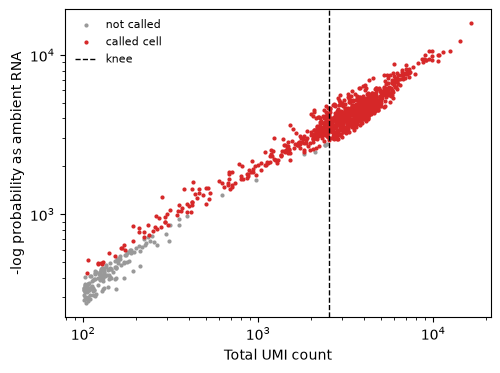

Started: 2026-10-22T16:52:39.297819Z | Wall time: 0.239 s

In [7]:
# Plot each tested barcode's total against minus its log-probability as ambient RNA.
fig, ax = plt.subplots(figsize=(5.5, 4))
for is_cell, color, name in ((False, "0.6", "not called"), (True, "tab:red", "called cell")):
    subset = table[table["called"] == is_cell]
    ax.scatter(subset["total"], -subset["log_probability"], s=4, color=color, label=name)

# Mark the total at which barcodes are kept without a test.
ax.axvline(calls.retain, color="black", linestyle="--", linewidth=1, label="knee")

# Label the axes and show the figure.
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Total UMI count",
    ylabel="-log probability as ambient RNA",
)
ax.legend(frameon=False, fontsize=8)
plt.show()

In [8]:
# Count the called cells with fewer counts than the knee.
below = table[table["called"] & (table["total"] < calls.retain)]
print(f"{len(below)} of {int(table['called'].sum())} called cells have fewer counts than the knee.")

# Summarize their totals.
below["total"].describe().round(0)

275 of 1045 called cells have fewer counts than the knee.


count     275.0
mean     1516.0
std       825.0
min       105.0
25%       706.0
50%      1698.0
75%      2290.0
max      2548.0
Name: total, dtype: float64

Started: 2026-10-22T16:52:39.540966Z | Wall time: 0.012 s

## Continue with quality control

The called cells are an ordinary cell selection: pass them as `cell_selection=` to the
quality-control filters and other analyses. Called cells still need quality control, because
EmptyDrops separates cells from empty droplets, not damaged cells from healthy ones.

Automatic filtering kept 917 of 1045 called cells.


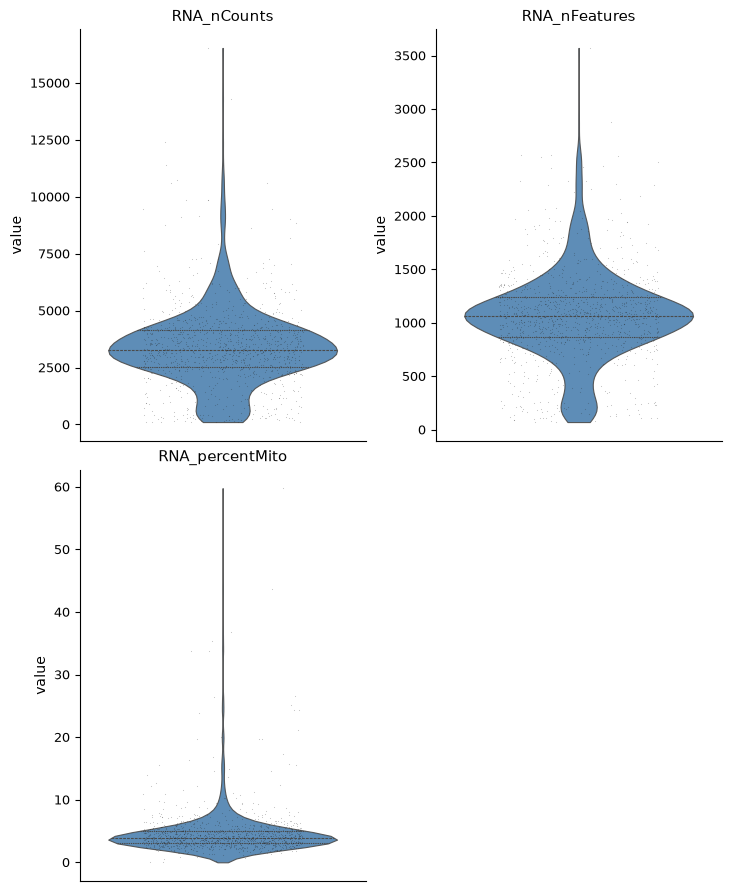

Started: 2026-10-22T16:52:39.556064Z | Wall time: 0.779 s

In [9]:
# Filter the called cells with the default robust thresholds.
filtered = ds.qc.auto_filter(cell_selection=cells)
kept = np.asarray(ds.artifacts.load(filtered)["values"][:], dtype=bool)
print(f"Automatic filtering kept {int(kept.sum())} of {int(called.sum())} called cells.")

# Inspect the quality measurements of the called cells.
ds.plots.distribution(
    keys=["RNA_nCounts", "RNA_nFeatures", "RNA_percentMito"], cell_selection=cells
)

The pipeline reads its cells from a cell key column, so record the called cells as one. Its
filtering stage then applies the same automatic thresholds to the called cells.

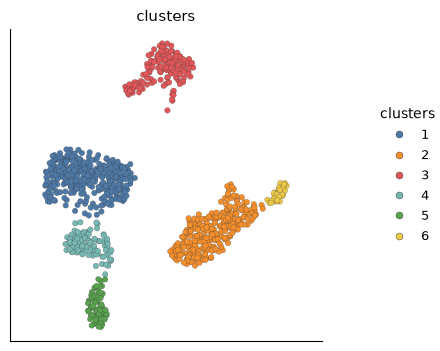

Started: 2026-10-22T16:52:40.338406Z | Wall time: 109.286 s

In [10]:
# Record the called cells as a cell key for the standard pipeline.
ds.cells.insert("called_cell", called)

# Run the standard analysis on the called cells.
run = ds.pipeline.run(
    label="called_cells",
    cell_key="called_cell",
    cell_cycle=False,
    paris=False,
    doublets=False,
)

# Show the clusters of the analyzed cells.
ds.plots.embedding(run=run, color_by="clusters")

## Common mistakes and limitations

- Importing with the default `filtering_cutoff=500` removes the ambient pool, and
  `qc.call_cells` raises. Import every barcode with a count, `filtering_cutoff=0`.
- Each capture has its own ambient pool. In a store that merges several captures, call cells for
  each capture with `cell_selection=` and combine the selections.
- `lower` must sit below the smallest cells and above most empty droplets. Barcodes at or below it
  are never called, and cells among them distort the ambient profile.
- Barcodes at or above `retain`, the knee by default, are cells without a test. Pass a larger
  `retain` to test them too.
- Cell calling does not remove ambient RNA from the called cells, and it does not detect
  doublets; those are separate steps.
- CyteArc implements EmptyDrops from its paper and supplementary methods. Its simulations use
  CyteArc's own random streams, so p-values near the threshold can differ from other
  implementations, by Monte Carlo error.